Ejemplo en Python con MiniSom (Librería de SOMs en Python)
Aquí tienes un ejemplo donde aplicamos SOM a un conjunto de datos de clasificación (Iris dataset).

In [1]:
!pip install minisom

  Preparing metadata (setup.py) ... done
  Created wheel for minisom: filename=MiniSom-2.3.5-py3-none-any.whl size=12031 sha256=c8aed99cde77b2adba6ac0e0b867c91bf4f0f2fed4eee948a8258d1df46c5ccd
  Stored in directory: /root/.cache/pip/wheels/19/db/95/5e53bc2b88a328217fdf9f2886cafbe86b0df274f4b601f572
Successfully built minisom


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from minisom import MiniSom
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler

In [3]:
# 1. Cargar datos (Iris dataset)
iris = load_iris()
X = iris.data
y = iris.target

In [4]:
# 2. Normalizar datos
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
# 3. Crear y entrenar el SOM (10x10 neuronas, 5000 iteraciones)
som = MiniSom(x=10, y=10, input_len=X.shape[1], sigma=1.0, learning_rate=0.5)
som.random_weights_init(X_scaled)
som.train_random(X_scaled, num_iteration=5000)

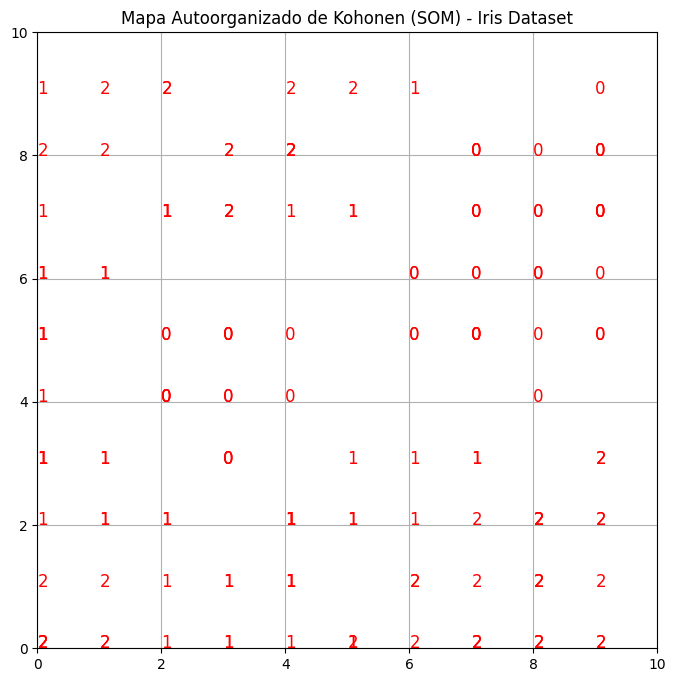

In [6]:
# 4. Visualizar el mapa de activación de las neuronas ganadoras
plt.figure(figsize=(8, 8))
for i, x in enumerate(X_scaled):
    winner = som.winner(x)  # Encontrar la BMU (neurona ganadora)
    plt.text(winner[0], winner[1], str(y[i]), color='red', fontsize=12)

plt.title("Mapa Autoorganizado de Kohonen (SOM) - Iris Dataset")
plt.xlim([0, 10])
plt.ylim([0, 10])
plt.grid()
plt.show()

Explicación del código:

1. Carga y normalización del dataset Iris.
2. Se define una red SOM de 10x10 neuronas.
3. Entrenamiento de la red con 5000 iteraciones.
4. Visualización del mapa con los datos proyectados en 2D.

¿Qué se observa en el mapa?

* Cada punto representa una neurona ganadora.
* Los números indican a qué clase pertenece cada dato (Iris setosa, versicolor o virginica).
* Las neuronas cercanas agrupan patrones similares.

